In [1]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold

#### Load and Prepare Data (3-horario)

In [2]:
import json
#### Las mismas 30 PCs de 02, pero desde las PCs horarias (no hace falta rehacer la PCA)
pcs_sel = json.load(open("outputs/seleccion_6h/seleccion.json"))["pcs"]
cols_msl = [c for c in pcs_sel if c.startswith("msl")]
cols_grad = [c for c in pcs_sel if c.startswith("grad")]
pcs_msl = pd.read_csv("outputs/pca/pcs_msl.csv", index_col=0, parse_dates=True, usecols=["time"] + cols_msl)
pcs_grad = pd.read_csv("outputs/pca/pcs_msl_gradient.csv", index_col=0, parse_dates=True, usecols=["time"] + cols_grad)
data_pcs_h = pcs_msl.join(pcs_grad)[pcs_sel]

waves_df_z = pd.read_csv("outputs/marginal/z_bulk.csv", index_col=0, parse_dates=True)   # PIT + armónica (00_PIT)

#### 3-horario: PCs en 00, 03, …, 21 h; Z = media de 3 h centrada
horas_3h = list(range(0, 24, 3))
data_pcs = data_pcs_h[data_pcs_h.index.hour.isin(horas_3h)]
waves_df_z_3h = waves_df_z.rolling("3h", center=True).mean()
waves_df_z_3h = waves_df_z_3h[waves_df_z_3h.index.hour.isin(horas_3h)].dropna()
print(data_pcs.shape, waves_df_z_3h.shape)

(253728, 30) (121984, 2)


In [3]:
lags = list(range(0, 37, 3))                                   # 0, 3, …, 36 h (13 retardos)
pcs_msl_lagged = pd.concat({f"l{l}": data_pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(data_pcs.index)
pcs_msl_lagged.columns = [f"{c}_l{l[1:]}" for l, c in pcs_msl_lagged.columns]
pcs_msl_lagged = pcs_msl_lagged.dropna()

idx = pcs_msl_lagged.index.intersection(waves_df_z_3h.index)
X = pcs_msl_lagged.loc[idx]
y = waves_df_z_3h.loc[idx, 'VHM0']
print(X.shape)

(121984, 390)


#### CrossValidation

In [4]:
tr = idx < "2016-01-01"
X_tr, y_tr = X[tr], y[tr]

In [5]:
f_oof = pd.Series(np.nan, index=X_tr.index)
for i_fit, i_val in GroupKFold(n_splits=6).split(X_tr, y_tr, groups=X_tr.index.year):
    xgboost_model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200,
                             subsample=0.8, colsample_bytree=0.8,
                       tree_method="hist", n_jobs=-1, random_state=0
    )
    xgboost_model.fit(X_tr.iloc[i_fit], y_tr.iloc[i_fit])
    f_oof.iloc[i_val] = xgboost_model.predict(X_tr.iloc[i_val])

#### Full model

In [6]:
xgb_final = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200,
                         subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)
xgb_final.fit(X_tr, y_tr)

#### f 3-horaria: OOF en 1985–2015, modelo final en 2016–2025
f_3h = pd.concat([f_oof, pd.Series(xgb_final.predict(X[~tr]), index=X.index[~tr])]).sort_index()

#### Comparación con 04B (6-horario)

In [7]:
#### f horaria de las dos versiones (interpolación lineal, como en 04B)
f_h_3 = f_3h.resample("h").interpolate()
res_6 = pd.read_csv("outputs/xgb_pit/residuos_horarios.csv", index_col=0, parse_dates=True)
f_h_6 = res_6["f"].asfreq("h")
z_hor = waves_df_z["VHM0"]

filas = []
for per, (a, b) in {"oof": ("1985", "2015"), "test": ("2016", "2025")}.items():
    for nombre, fh in [("6h (04B)", f_h_6), ("3h (04C)", f_h_3)]:
        fh = fh.loc[a:b]
        zh = z_hor.reindex(fh.index)
        filas.append({"periodo": per, "f": nombre, "corr h": fh.corr(zh),
                      "corr diaria": fh.resample("D").mean().corr(zh.resample("D").mean())})
    filas.append({"periodo": per, "f": "3h nativa vs Z 3h", "corr h": f_3h.loc[a:b].corr(y.loc[a:b])})
print(pd.DataFrame(filas).set_index(["periodo", "f"]).round(3).to_string())

                           corr h  corr diaria
periodo f                                     
oof     6h (04B)            0.784        0.824
        3h (04C)            0.785        0.826
        3h nativa vs Z 3h   0.786          NaN
test    6h (04B)            0.770        0.811
        3h (04C)            0.770        0.812
        3h nativa vs Z 3h   0.772          NaN


In [8]:
from scipy.signal import find_peaks
ventana = np.arange(-48, 49)

def metricas_picos(f_h, z_h, q=0.99):
    """Z observado alrededor de los máximos locales de f (> q): ¿f se pasa? ¿llega tarde?"""
    pk, _ = find_peaks(f_h.values, height=f_h.quantile(q), distance=72)
    pk = pk[(pk > 48) & (pk < len(f_h) - 49)]
    comp_z = np.nanmean([z_h.values[i + ventana] for i in pk], axis=0)
    comp_f = np.nanmean([f_h.values[i + ventana] for i in pk], axis=0)
    return {"n picos": len(pk),
            "r en pico": np.nanmean(z_h.values[pk] - f_h.values[pk]),            # <0: f se pasa en su pico
            "Δ pico compuesto": comp_z.max() - comp_f.max(),                      # <0: el pico medio de f es más alto
            "desfase h": ventana[np.argmax(comp_z)] - ventana[np.argmax(comp_f)], # <0: Z observado pica antes que f
            "exceso máx ±24h": np.nanmean([np.nanmax(z_h.values[i - 24:i + 25]) - f_h.values[i] for i in pk])}, comp_z - comp_f

filas, sesgo = [], {}
for per, (a, b) in {"oof": ("1985", "2015"), "test": ("2016", "2025")}.items():
    for nombre, fh in [("6h (04B)", f_h_6), ("3h (04C)", f_h_3)]:
        fh = fh.loc[a:b]
        m_pk, sesgo[(per, nombre)] = metricas_picos(fh, z_hor.reindex(fh.index))
        filas.append({"periodo": per, "f": nombre, **m_pk})
print(pd.DataFrame(filas).set_index(["periodo", "f"]).round(3).to_string())

                  n picos  r en pico  Δ pico compuesto  desfase h  exceso máx ±24h
periodo f                                                                         
oof     6h (04B)      141     -0.147            -0.125         -2            0.181
        3h (04C)      155     -0.217            -0.203         -2            0.109
test    6h (04B)       52     -0.289            -0.289          0            0.066
        3h (04C)       49     -0.398            -0.357         -3           -0.019


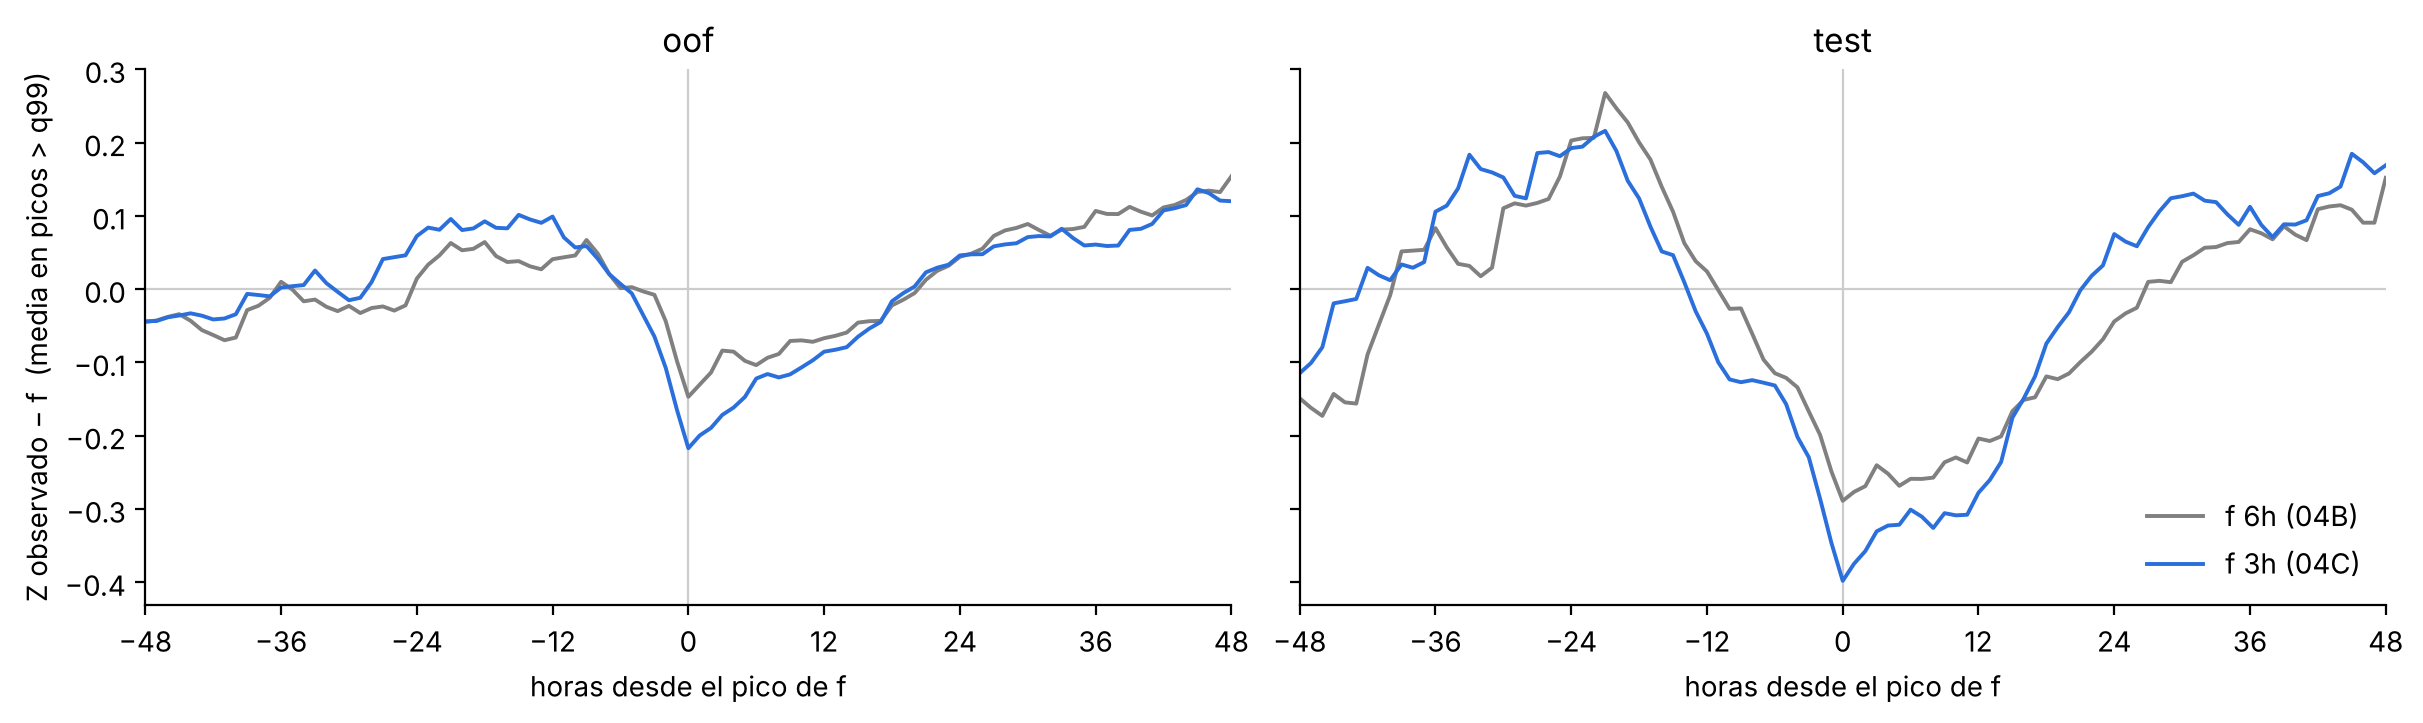

In [9]:
#### Sesgo medio de f alrededor de sus picos (Z observado − f): ¿desaparece la V con f 3-horaria?
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True, constrained_layout=True)
colores = {"6h (04B)": "0.5", "3h (04C)": "#2a6fdb"}
for ax, per in zip(axs, ["oof", "test"]):
    for nombre in colores:
        ax.plot(ventana, sesgo[(per, nombre)], color=colores[nombre], lw=1.4, label=f"f {nombre}")
    ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    ax.axvline(0, color="0.8", lw=0.8, zorder=0)
    ax.set(title=per, xlabel="horas desde el pico de f", xticks=np.arange(-48, 49, 12), xlim=(-48, 48))
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("Z observado − f  (media en picos > q99)")
axs[1].legend(frameon=False, loc="lower right")
plt.show()

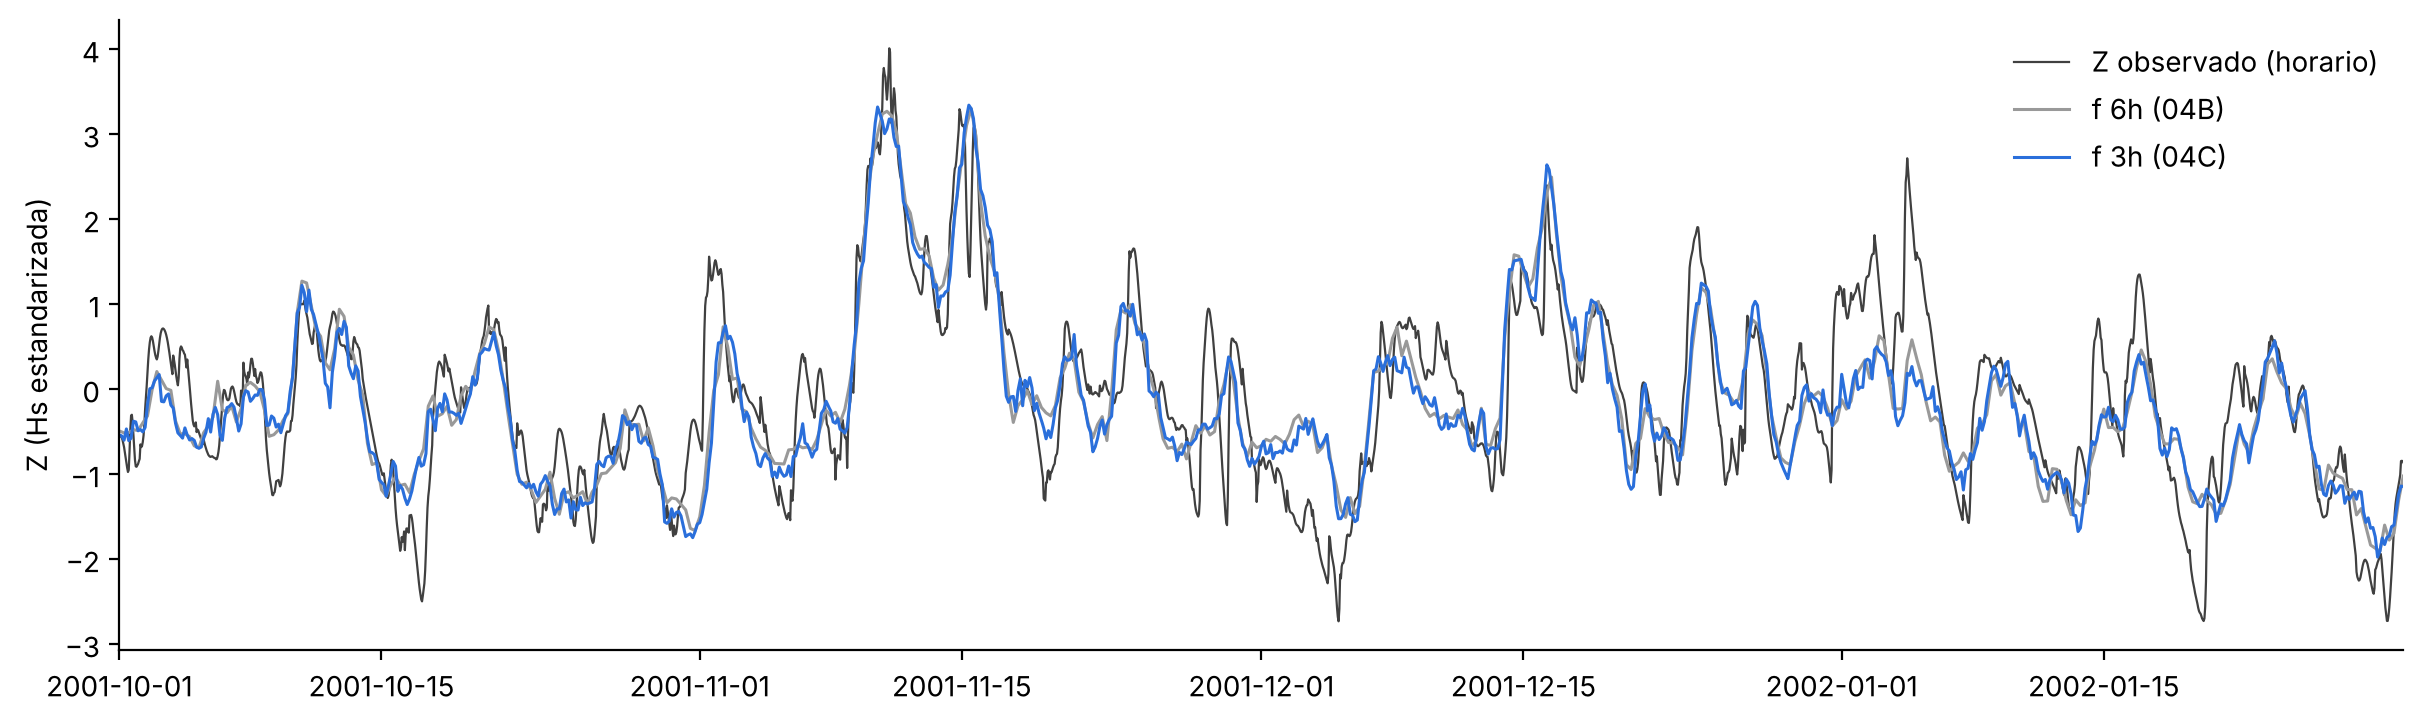

In [10]:
t0, t1 = "2001-10-01", "2002-01-31"

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.plot(z_hor.loc[t0:t1], color="0.25", lw=0.8, label="Z observado (horario)")
ax.plot(f_h_6.loc[t0:t1], color="0.6", lw=1.1, label="f 6h (04B)")
ax.plot(f_h_3.loc[t0:t1], color="#2a6fdb", lw=1.1, label="f 3h (04C)")
ax.set(ylabel="Z (Hs estandarizada)", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

In [11]:
import os
os.makedirs("outputs/xgb_pit_3h", exist_ok=True)

#### Modelo final + orden de columnas que espera
xgb_final.save_model("outputs/xgb_pit_3h/xgb_final.json")
with open("outputs/xgb_pit_3h/xgb_features.json", "w") as f:
    json.dump({"columns": list(X_tr.columns), "lags_h": lags, "train": ["1985-01-01", "2015-12-31"]}, f, indent=1)

#### Serie horaria (mismo formato que 04B, para usarla en 05C) y serie 3-horaria nativa
z_h = z_hor.reindex(f_h_3.index)
residuos = pd.DataFrame({"z": z_h, "f": f_h_3, "r": z_h - f_h_3})
residuos["periodo"] = np.where(residuos.index < "2016-01-01", "oof", "test")
residuos.dropna(subset=["r"]).to_csv("outputs/xgb_pit_3h/residuos_horarios.csv")

residuos_3h = pd.DataFrame({"z": y, "f": f_3h.reindex(y.index), "r": y - f_3h.reindex(y.index)})
residuos_3h["periodo"] = np.where(residuos_3h.index < "2016-01-01", "oof", "test")
residuos_3h.dropna().to_csv("outputs/xgb_pit_3h/residuos_3h.csv")
print(residuos.dropna().groupby("periodo")["r"].agg(["count", "std"]))

          count       std
periodo                  
oof      271728  0.620828
test      94222  0.630749
